First, import the dataset and show the first five rows:



In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/ecb_monetary_policy_monthly.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,date,eu27_hicp_yoy_pct,deposit_facility_rate_pct
0,2004-01-01,2.1,1.0
1,2004-02-01,2.0,1.0
2,2004-03-01,2.0,1.0
3,2004-04-01,2.3,1.0
4,2004-05-01,2.8,1.0


Now, create a plot showing the inflation rate (eu27_hicp_yoy_pct) and the  interest rates (deposit_facility_rate_pct).

In this case, use the library matplotlib to display a static graph.

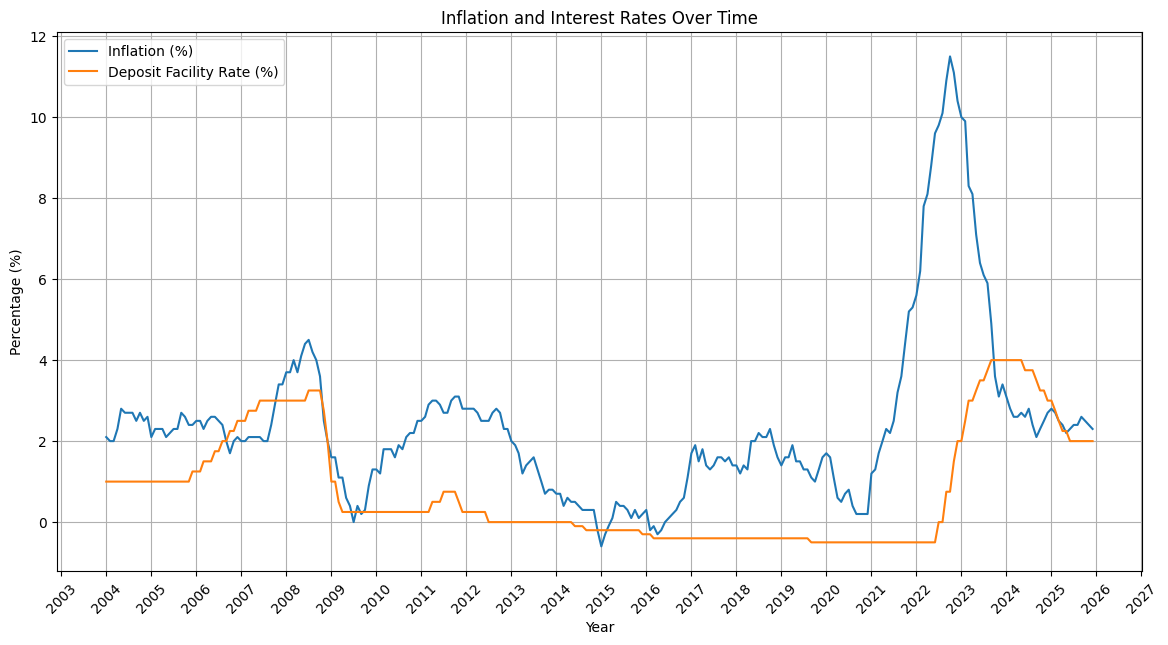

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

# Ensure 'date' is datetime if not already
df['date'] = pd.to_datetime(df['date'])

# Plotting the data
plt.figure(figsize=(14, 7))
plt.plot(df['date'], df['eu27_hicp_yoy_pct'], label='Inflation (%)')
plt.plot(df['date'], df['deposit_facility_rate_pct'], label='Deposit Facility Rate (%)')

# Format x-axis to only show years
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.title('Inflation and Interest Rates Over Time')
plt.xlabel('Year')
plt.ylabel('Percentage (%)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

Now, instead of using the matplotlib library to show a static plot, use the library plotly to interact with the datapoints and zoom in the desired date ranges.

In [5]:
import plotly.graph_objects as go

# Create the plotly figure
fig = go.Figure()

# Add Inflation line
fig.add_trace(go.Scatter(x=df['date'], y=df['eu27_hicp_yoy_pct'],
                    mode='lines',
                    name='Inflation (%)'))

# Add Interest Rate line
fig.add_trace(go.Scatter(x=df['date'], y=df['deposit_facility_rate_pct'],
                    mode='lines',
                    name='Deposit Facility Rate (%)'))

# Update layout for cleaner x-axis and titles
fig.update_layout(
    title='Inflation and Interest Rates Over Time',
    xaxis_title='Year',
    yaxis_title='Percentage (%)',
    hovermode='x unified',
    xaxis=dict(
        dtick="M12",
        tickformat="%Y",
        ticklabelmode="period"
    )
)

fig.show()